In [1]:
# ============================================================
# Predicción de abandono de clientes — IBM Telco Customer Churn
# Documentación completa: DOCUMENTACION.md
# Kernel: Python 3.15 (Telco Churn)
# ============================================================

# 1. Configuración e importaciones
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
import xgboost
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    average_precision_score,
    f1_score,
    make_scorer,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedKFold,
    cross_val_predict,
    cross_validate,
    train_test_split,
)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier

# Reproducibilidad y rutas
RANDOM_STATE = 42
TEST_SIZE = 0.20
DATA_PATH = Path("data/WA_Fn-UseC_-Telco-Customer-Churn.csv")
TARGET = "Churn"

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda valor: f"{valor:,.3f}")
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110

print(f"Python      : {sys.version.split()[0]}")
print(f"pandas      : {pd.__version__}")
print(f"scikit-learn: {sklearn.__version__}")
print(f"XGBoost     : {xgboost.__version__}")

Python      : 3.15.2
pandas      : 3.1.1
scikit-learn: 1.9.1
XGBoost     : 3.4.1


In [2]:
# 2. Carga y revisión inicial
df = pd.read_csv(DATA_PATH)

print(f"Registros: {df.shape[0]:,} | Columnas: {df.shape[1]}")
print(f"Clientes únicos: {df['customerID'].nunique():,}")
df.head()

Registros: 7,043 | Columnas: 21
Clientes únicos: 7,043


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.850,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.950,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.850,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.300,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.700,151.65,Yes


In [3]:
# Tipos, nulos y cardinalidad de cada variable
resumen = pd.DataFrame(
    {
        "tipo": df.dtypes.astype(str),
        "nulos": df.isna().sum(),
        "valores_unicos": df.nunique(),
        "ejemplo": df.iloc[0],
    }
)
resumen

,tipo,nulos,valores_unicos,ejemplo
customerID,str,0,7043,7590-VHVEG
gender,str,0,2,Female
SeniorCitizen,int64,0,2,0
Partner,str,0,2,Yes
Dependents,str,0,2,No
tenure,int64,0,73,1
PhoneService,str,0,2,No
MultipleLines,str,0,3,No phone service
InternetService,str,0,3,DSL
OnlineSecurity,str,0,3,No


In [4]:
# Distribución del objetivo: 26,54 % de abandono
conteo = df[TARGET].value_counts().rename(index={"No": "No abandona", "Yes": "Abandona"})
tabla_objetivo = pd.DataFrame(
    {
        "clientes": conteo,
        "porcentaje": (conteo / len(df) * 100).round(2),
    }
)
print(tabla_objetivo.to_string())

# TotalCharges llega como texto por 11 espacios en blanco
print("\nValores no numéricos en TotalCharges:")
no_numericos = pd.to_numeric(df["TotalCharges"], errors="coerce").isna()
print(f"  {no_numericos.sum()} registros")
print(df.loc[no_numericos, ["tenure", "MonthlyCharges", "TotalCharges"]].to_string(index=False))

             clientes  porcentaje
Churn                            
No abandona      5174      73.460
Abandona         1869      26.540

Valores no numéricos en TotalCharges:
  11 registros
 tenure  MonthlyCharges TotalCharges
      0          52.550             
      0          20.250             
      0          80.850             
      0          25.750             
      0          56.050             
      0          19.850             
      0          25.350             
      0          20.000             
      0          19.700             
      0          73.350             
      0          61.900             


In [5]:
# 3. Depuración
# Los 11 faltantes de TotalCharges tienen tenure = 0: clientes nuevos sin facturación
# acumulada. Se imputan con 0 dentro del pipeline, no con la mediana.
df = df.copy()
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df[TARGET] = df[TARGET].map({"No": 0, "Yes": 1})

assert df["customerID"].is_unique, "Hay identificadores duplicados"
assert df[TARGET].notna().all(), "La variable objetivo contiene valores no reconocidos"

print(f"TotalCharges faltante: {df['TotalCharges'].isna().sum()} casos")
print(f"Tasa de abandono: {df[TARGET].mean():.2%}")

TotalCharges faltante: 11 casos
Tasa de abandono: 26.54%


In [6]:
# 4. Partición estratificada 80/20
# Se divide antes de cualquier transformación para evitar fuga de información.
# customerID se excluye: identifica al cliente, no describe su comportamiento.
X = df.drop(columns=["customerID", TARGET])
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    stratify=y,
    random_state=RANDOM_STATE,
)

print(f"Entrenamiento: {X_train.shape[0]:,} clientes | abandono {y_train.mean():.2%}")
print(f"Prueba       : {X_test.shape[0]:,} clientes | abandono {y_test.mean():.2%}")

Entrenamiento: 5,634 clientes | abandono 26.54%
Prueba       : 1,409 clientes | abandono 26.54%


In [7]:
# 5. Análisis exploratorio (solo entrenamiento)
# Se comparan tasas, no conteos: un segmento grande puede tener más casos sin mayor riesgo.
train = X_train.assign(Churn=y_train)


def tasa_por(columna):
    tabla = (
        train.groupby(columna, observed=True)["Churn"]
        .agg(clientes="size", tasa="mean")
        .sort_values("tasa", ascending=False)
    )
    tabla["tasa"] = (tabla["tasa"] * 100).round(1)
    return tabla


for variable in ["Contract", "InternetService", "PaymentMethod", "TechSupport"]:
    print(f"\nTasa de abandono por {variable} (%):")
    print(tasa_por(variable).to_string())


Tasa de abandono por Contract (%):
                clientes   tasa
Contract                       
Month-to-month      3102 42.700
One year            1173 11.100
Two year            1359  2.900

Tasa de abandono por InternetService (%):
                 clientes   tasa
InternetService                 
Fiber optic          2483 42.100
DSL                  1937 18.700
No                   1214  7.200

Tasa de abandono por PaymentMethod (%):
                           clientes   tasa
PaymentMethod                             
Electronic check               1891 45.700
Mailed check                   1286 19.300
Bank transfer (automatic)      1244 16.200
Credit card (automatic)        1213 14.900

Tasa de abandono por TechSupport (%):
                     clientes   tasa
TechSupport                         
No                       2771 41.800
Yes                      1649 15.200
No internet service      1214  7.200


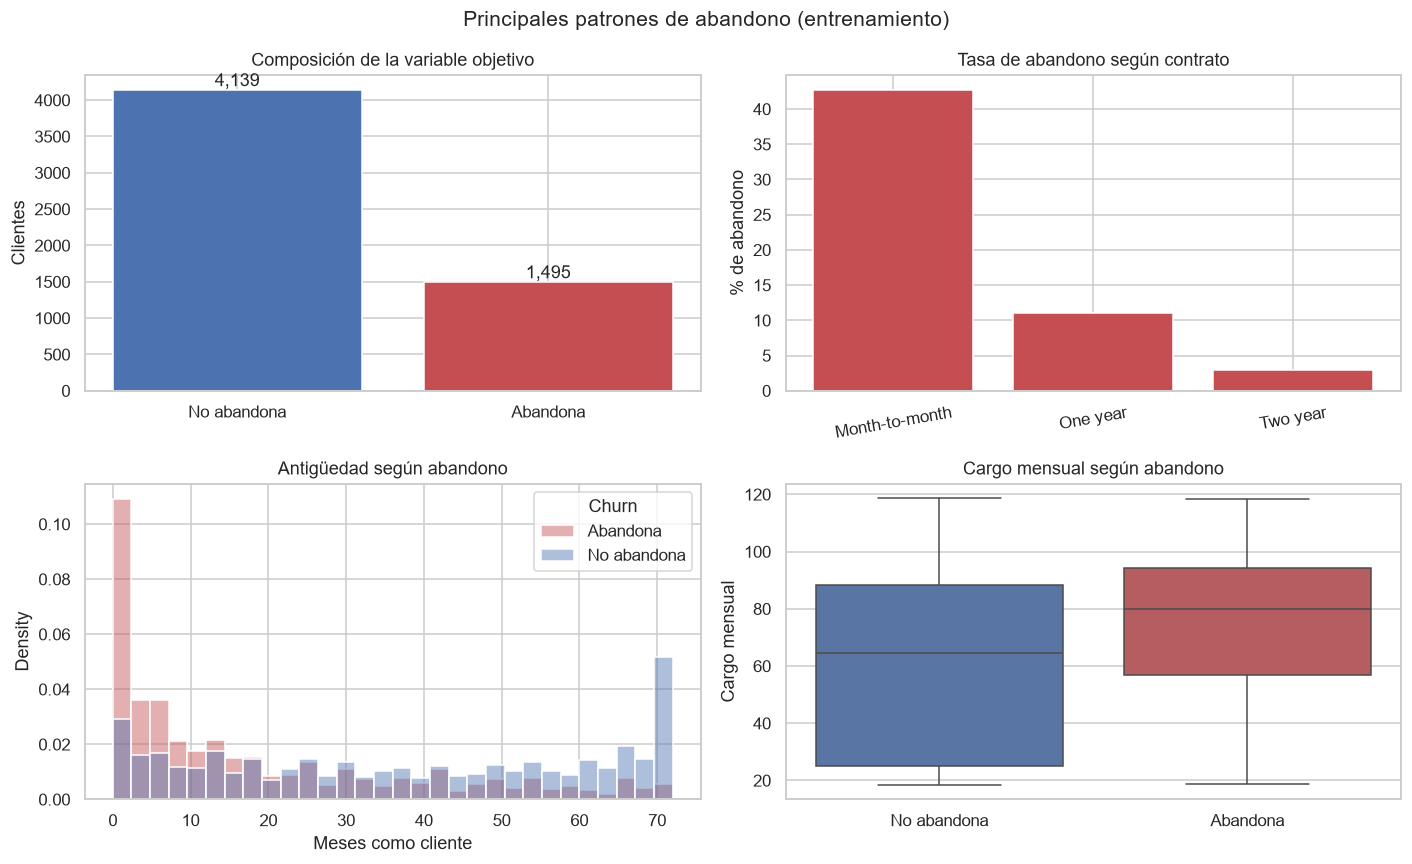

In [8]:
# Figura 1: objetivo, contrato, antigüedad y cargo mensual
fig, axes = plt.subplots(2, 2, figsize=(13, 8))

conteo = train["Churn"].map({0: "No abandona", 1: "Abandona"}).value_counts()
axes[0, 0].bar(conteo.index, conteo.values, color=["#4C72B0", "#C44E52"])
axes[0, 0].set_title("Composición de la variable objetivo")
axes[0, 0].set_ylabel("Clientes")
for i, valor in enumerate(conteo.values):
    axes[0, 0].text(i, valor, f"{valor:,}", ha="center", va="bottom")

tasa_contrato = tasa_por("Contract")
axes[0, 1].bar(tasa_contrato.index, tasa_contrato["tasa"], color="#C44E52")
axes[0, 1].set_title("Tasa de abandono según contrato")
axes[0, 1].set_ylabel("% de abandono")
axes[0, 1].tick_params(axis="x", rotation=10)

sns.histplot(
    data=train,
    x="tenure",
    hue="Churn",
    bins=30,
    stat="density",
    common_norm=False,
    palette={0: "#4C72B0", 1: "#C44E52"},
    alpha=0.45,
    ax=axes[1, 0],
)
axes[1, 0].set_title("Antigüedad según abandono")
axes[1, 0].set_xlabel("Meses como cliente")
axes[1, 0].legend(title="Churn", labels=["Abandona", "No abandona"])

sns.boxplot(
    data=train,
    x="Churn",
    y="MonthlyCharges",
    hue="Churn",
    palette={0: "#4C72B0", 1: "#C44E52"},
    legend=False,
    ax=axes[1, 1],
)
axes[1, 1].set_title("Cargo mensual según abandono")
axes[1, 1].set_xlabel("")
axes[1, 1].set_xticks([0, 1], ["No abandona", "Abandona"])
axes[1, 1].set_ylabel("Cargo mensual")

fig.suptitle("Principales patrones de abandono (entrenamiento)", fontsize=14)
fig.tight_layout()
plt.show()

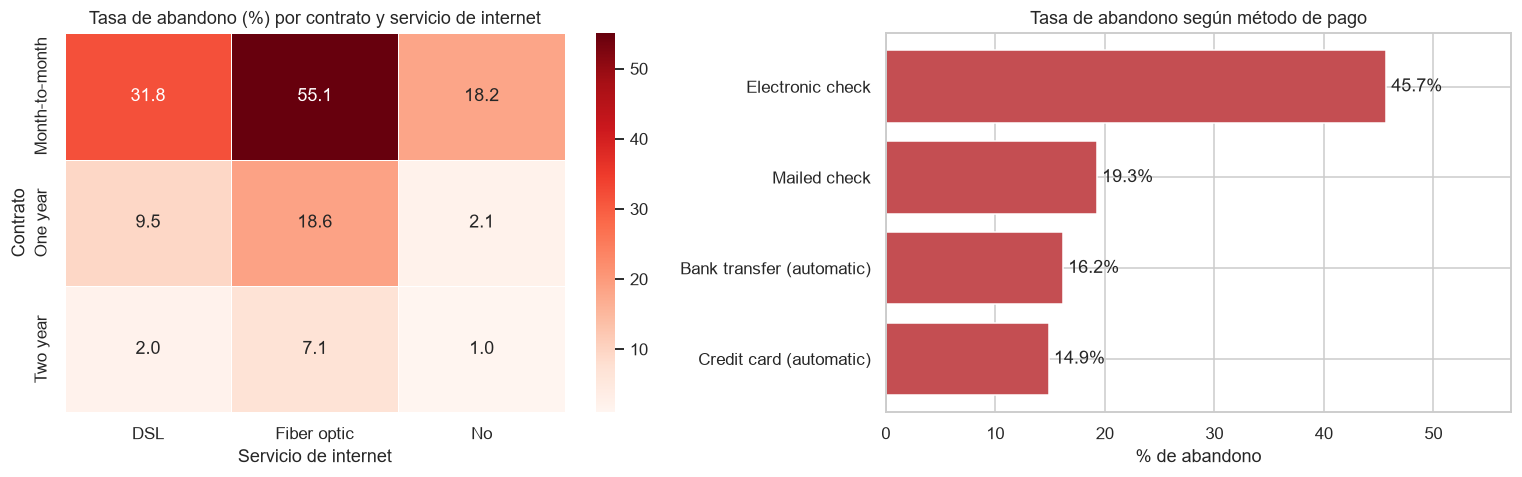

In [9]:
# Figura 2: contrato x internet y método de pago
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

pivote = (
    train.pivot_table(index="Contract", columns="InternetService", values="Churn", aggfunc="mean")
    * 100
)
sns.heatmap(pivote, annot=True, fmt=".1f", cmap="Reds", linewidths=0.5, ax=axes[0])
axes[0].set_title("Tasa de abandono (%) por contrato y servicio de internet")
axes[0].set_xlabel("Servicio de internet")
axes[0].set_ylabel("Contrato")

tasa_pago = tasa_por("PaymentMethod")
axes[1].barh(tasa_pago.index[::-1], tasa_pago["tasa"][::-1], color="#C44E52")
axes[1].set_title("Tasa de abandono según método de pago")
axes[1].set_xlabel("% de abandono")
axes[1].set_xlim(0, max(tasa_pago["tasa"]) * 1.25)
for i, valor in enumerate(tasa_pago["tasa"][::-1]):
    axes[1].text(valor, i, f" {valor:.1f}%", va="center")

fig.tight_layout()
plt.show()

In [10]:
# 6. Preparación de variables
# Todo se aprende dentro del pipeline y de cada partición de validación.
NUMERICAS_MEDIANA = ["tenure", "MonthlyCharges"]
NUMERICAS_CERO = ["TotalCharges"]
CATEGORICAS = [
    columna
    for columna in X_train.columns
    if columna not in NUMERICAS_MEDIANA + NUMERICAS_CERO
]

rama_mediana = Pipeline(
    [
        ("imputar", SimpleImputer(strategy="median")),
        ("escalar", StandardScaler()),
    ]
)

# TotalCharges faltante = cliente nuevo sin facturación acumulada
rama_cero = Pipeline(
    [
        ("imputar", SimpleImputer(strategy="constant", fill_value=0)),
        ("escalar", StandardScaler()),
    ]
)

rama_categorica = Pipeline(
    [
        ("imputar", SimpleImputer(strategy="most_frequent")),
        ("codificar", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ]
)

preprocesador = ColumnTransformer(
    [
        ("num_mediana", rama_mediana, NUMERICAS_MEDIANA),
        ("num_cero", rama_cero, NUMERICAS_CERO),
        ("cat", rama_categorica, CATEGORICAS),
    ]
)

print(f"Variables numéricas (mediana): {NUMERICAS_MEDIANA}")
print(f"Variables numéricas (cero)   : {NUMERICAS_CERO}")
print(f"Variables categóricas        : {len(CATEGORICAS)}")
print(", ".join(CATEGORICAS))

Variables numéricas (mediana): ['tenure', 'MonthlyCharges']
Variables numéricas (cero)   : ['TotalCharges']
Variables categóricas        : 16
gender, SeniorCitizen, Partner, Dependents, PhoneService, MultipleLines, InternetService, OnlineSecurity, OnlineBackup, DeviceProtection, TechSupport, StreamingTV, StreamingMovies, Contract, PaperlessBilling, PaymentMethod


In [11]:
# 7. Modelos y grillas de hiperparámetros
# class_weight / scale_pos_weight dan más peso a la clase minoritaria.
MODELOS = {
    "Regresión logística": {
        "estimador": LogisticRegression(
            max_iter=2000,
            class_weight="balanced",
            random_state=RANDOM_STATE,
        ),
        "grilla": {"clf__C": [0.1, 1.0, 10.0]},
    },
    "KNN": {
        "estimador": KNeighborsClassifier(),
        "grilla": {
            "clf__n_neighbors": [5, 15, 31],
            "clf__weights": ["uniform", "distance"],
        },
    },
    "Árbol de decisión": {
        "estimador": DecisionTreeClassifier(
            class_weight="balanced",
            random_state=RANDOM_STATE,
        ),
        "grilla": {
            "clf__max_depth": [3, 5, 7],
            "clf__min_samples_leaf": [5, 20],
        },
    },
    "Random Forest": {
        "estimador": RandomForestClassifier(
            n_estimators=300,
            class_weight="balanced",
            random_state=RANDOM_STATE,
            n_jobs=1,
        ),
        "grilla": {
            "clf__max_depth": [None, 8],
            "clf__min_samples_leaf": [1, 5],
        },
    },
    "XGBoost": {
        "estimador": XGBClassifier(
            n_estimators=300,
            learning_rate=0.05,
            subsample=0.8,
            colsample_bytree=0.8,
            scale_pos_weight=float((y_train == 0).sum() / (y_train == 1).sum()),
            eval_metric="logloss",
            random_state=RANDOM_STATE,
            n_jobs=1,
        ),
        "grilla": {
            "clf__max_depth": [3, 5],
            "clf__learning_rate": [0.05, 0.1],
        },
    },
}

print("Modelos configurados:")
for nombre in MODELOS:
    print(f"  - {nombre}")

Modelos configurados:
  - Regresión logística
  - KNN
  - Árbol de decisión
  - Random Forest
  - XGBoost


In [12]:
# 8. Línea base trivial
# "Siempre no abandona" alcanza ~73,5 % de accuracy con recall 0:
# demuestra por qué la accuracy no sirve como métrica principal.
METRICAS = {
    "average_precision": "Average precision",
    "roc_auc": "ROC-AUC",
    "recall": "Recall",
    "precision": "Precision",
    "f1": "F1",
    "accuracy": "Accuracy",
}

SCORING = {
    "average_precision": "average_precision",
    "roc_auc": "roc_auc",
    "recall": "recall",
    "precision": make_scorer(precision_score, zero_division=0),
    "f1": make_scorer(f1_score, zero_division=0),
    "accuracy": "accuracy",
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

baseline = DummyClassifier(strategy="most_frequent")
cv_baseline = cross_validate(baseline, X_train, y_train, cv=cv, scoring=SCORING)

tabla_baseline = pd.DataFrame(
    {
        etiqueta: f"{cv_baseline[f'test_{metrica}'].mean():.3f} ± "
        f"{cv_baseline[f'test_{metrica}'].std():.3f}"
        for metrica, etiqueta in METRICAS.items()
    },
    index=["Siempre 'no abandona'"],
).T

tabla_baseline.columns = ["Resultado"]
tabla_baseline

,Resultado
Average precision,0.265 ± 0.000
ROC-AUC,0.500 ± 0.000
Recall,0.000 ± 0.000
Precision,0.000 ± 0.000
F1,0.000 ± 0.000
Accuracy,0.735 ± 0.000


In [13]:
# 9. Ajuste de hiperparámetros
# GridSearchCV con validación cruzada estratificada; se selecciona por average precision.
resultados_ajuste = {}

for nombre, configuracion in MODELOS.items():
    pipeline = Pipeline(
        [
            ("preprocesador", preprocesador),
            ("clf", configuracion["estimador"]),
        ]
    )
    busqueda = GridSearchCV(
        estimator=pipeline,
        param_grid=configuracion["grilla"],
        scoring="average_precision",
        cv=cv,
        refit=True,
        n_jobs=-1,
    )

    inicio = time.perf_counter()
    busqueda.fit(X_train, y_train)
    duracion = time.perf_counter() - inicio

    resultados_ajuste[nombre] = {
        "busqueda": busqueda,
        "mejores_parametros": busqueda.best_params_,
        "ap_validacion": busqueda.best_score_,
        "segundos": duracion,
    }

    parametros = ", ".join(
        f"{clave.replace('clf__', '')}={valor}"
        for clave, valor in busqueda.best_params_.items()
    )
    print(
        f"{nombre:<22} AP={busqueda.best_score_:.4f} | "
        f"{duracion:6.1f} s | {parametros}"
    )

Regresión logística    AP=0.6601 |   14.9 s | C=1.0


KNN                    AP=0.6201 |    2.8 s | n_neighbors=31, weights=uniform


Árbol de decisión      AP=0.6204 |    1.6 s | max_depth=7, min_samples_leaf=20


Random Forest          AP=0.6615 |   20.6 s | max_depth=8, min_samples_leaf=5


XGBoost                AP=0.6683 |    6.0 s | learning_rate=0.05, max_depth=3


In [14]:
# 9.1 Comparación de los modelos ajustados en validación cruzada
mejores_modelos = {
    nombre: resultado["busqueda"].best_estimator_
    for nombre, resultado in resultados_ajuste.items()
}

filas = []
for nombre, modelo in mejores_modelos.items():
    cv_resultado = cross_validate(
        modelo,
        X_train,
        y_train,
        cv=cv,
        scoring=SCORING,
        n_jobs=1,
    )
    fila = {"Modelo": nombre}
    for metrica, etiqueta in METRICAS.items():
        valores = cv_resultado[f"test_{metrica}"]
        fila[etiqueta] = f"{valores.mean():.3f} ± {valores.std():.3f}"
    fila["AP (media)"] = cv_resultado["test_average_precision"].mean()
    filas.append(fila)

tabla_cv = (
    pd.DataFrame(filas)
    .sort_values("AP (media)", ascending=False)
    .drop(columns="AP (media)")
    .reset_index(drop=True)
)
tabla_cv.insert(0, "Puesto", tabla_cv.index + 1)
tabla_cv

,Puesto,Modelo,Average precision,ROC-AUC,Recall,Precision,F1,Accuracy
0,1,XGBoost,0.668 ± 0.021,0.847 ± 0.011,0.791 ± 0.025,0.522 ± 0.011,0.629 ± 0.015,0.752 ± 0.008
1,2,Random Forest,0.662 ± 0.018,0.848 ± 0.009,0.793 ± 0.024,0.525 ± 0.016,0.632 ± 0.015,0.755 ± 0.012
2,3,Regresión logística,0.660 ± 0.020,0.846 ± 0.012,0.801 ± 0.038,0.517 ± 0.019,0.628 ± 0.023,0.748 ± 0.015
3,4,Árbol de decisión,0.620 ± 0.016,0.817 ± 0.010,0.780 ± 0.022,0.507 ± 0.032,0.614 ± 0.028,0.739 ± 0.025
4,5,KNN,0.620 ± 0.012,0.835 ± 0.009,0.583 ± 0.022,0.621 ± 0.023,0.601 ± 0.021,0.795 ± 0.011


In [15]:
# 10. Ajuste del umbral de decisión
# Se maximiza F1 sobre predicciones out-of-fold: el conjunto de prueba no participa.
umbrales = {}
resumen_umbral = []

for nombre, modelo in mejores_modelos.items():
    probabilidad_oof = cross_val_predict(
        modelo,
        X_train,
        y_train,
        cv=cv,
        method="predict_proba",
        n_jobs=1,
    )[:, 1]

    precision, recall, umbrales_candidatos = precision_recall_curve(
        y_train, probabilidad_oof
    )
    f1 = np.divide(
        2 * precision * recall,
        precision + recall,
        out=np.zeros_like(precision),
        where=(precision + recall) > 0,
    )
    indice = int(np.argmax(f1[:-1]))
    umbral = float(umbrales_candidatos[indice])
    umbrales[nombre] = umbral

    resumen_umbral.append(
        {
            "Modelo": nombre,
            "Umbral": round(umbral, 3),
            "F1 (OOF)": round(float(f1[indice]), 3),
            "Recall (OOF)": round(float(recall[indice]), 3),
            "Precision (OOF)": round(float(precision[indice]), 3),
        }
    )

pd.DataFrame(resumen_umbral).sort_values("F1 (OOF)", ascending=False).reset_index(drop=True)

,Modelo,Umbral,F1 (OOF),Recall (OOF),Precision (OOF)
0,Regresión logística,0.576,0.638,0.743,0.558
1,XGBoost,0.585,0.636,0.718,0.571
2,Random Forest,0.531,0.636,0.767,0.544
3,KNN,0.452,0.623,0.668,0.584
4,Árbol de decisión,0.525,0.615,0.761,0.516


In [16]:
# 11. Evaluación final sobre el conjunto de prueba
# Se comparan las probabilidades con el umbral 0,5 y con el umbral ajustado en validación.
probabilidades_test = {}
predicciones_test = {}
filas = []

for nombre, modelo in mejores_modelos.items():
    probabilidad = modelo.predict_proba(X_test)[:, 1]
    umbral = umbrales[nombre]
    prediccion = (probabilidad >= umbral).astype(int)

    probabilidades_test[nombre] = probabilidad
    predicciones_test[nombre] = prediccion

    filas.append(
        {
            "Modelo": nombre,
            "Average precision": average_precision_score(y_test, probabilidad),
            "ROC-AUC": roc_auc_score(y_test, probabilidad),
            "Recall @0,5": recall_score(y_test, (probabilidad >= 0.5).astype(int)),
            "Precision @0,5": precision_score(y_test, (probabilidad >= 0.5).astype(int)),
            "F1 @0,5": f1_score(y_test, (probabilidad >= 0.5).astype(int)),
            "Umbral ajustado": umbral,
            "Recall (umbral ajustado)": recall_score(y_test, prediccion),
            "Precision (umbral ajustado)": precision_score(y_test, prediccion),
            "F1 (umbral ajustado)": f1_score(y_test, prediccion),
            "Accuracy (umbral ajustado)": accuracy_score(y_test, prediccion),
        }
    )

tabla_prueba = (
    pd.DataFrame(filas)
    .set_index("Modelo")
    .sort_values("Average precision", ascending=False)
)
tabla_prueba.round(3)

,Average precision,ROC-AUC,"Recall @0,5","Precision @0,5","F1 @0,5",Umbral ajustado,Recall (umbral ajustado),Precision (umbral ajustado),F1 (umbral ajustado),Accuracy (umbral ajustado)
Modelo,,,,,,,,,,
XGBoost,0.664,0.845,0.789,0.525,0.630,0.585,0.719,0.552,0.625,0.771
Random Forest,0.651,0.843,0.791,0.521,0.628,0.531,0.767,0.534,0.630,0.761
Regresión logística,0.633,0.842,0.783,0.504,0.614,0.576,0.725,0.539,0.618,0.762
Árbol de decisión,0.625,0.825,0.799,0.498,0.613,0.525,0.770,0.507,0.611,0.740
KNN,0.611,0.831,0.580,0.608,0.594,0.452,0.652,0.565,0.605,0.774


In [17]:
# 12. Capacidad operativa: contacto al 20 % de mayor riesgo
# Cuántos abandonos reales quedan cubiertos si el equipo solo puede llamar a ese 20 %.
filas_top20 = []

for nombre in tabla_prueba.index:
    probabilidad = probabilidades_test[nombre]
    corte = np.quantile(probabilidad, 0.80)
    seleccionados = probabilidad >= corte

    filas_top20.append(
        {
            "Modelo": nombre,
            "Clientes contactados": int(seleccionados.sum()),
            "% de la cartera": seleccionados.mean() * 100,
            "Abandonos detectados": int(y_test[seleccionados].sum()),
            "Cobertura de abandonos": y_test[seleccionados].sum() / y_test.sum(),
            "Precision en el grupo": y_test[seleccionados].mean(),
        }
    )

tabla_top20 = (
    pd.DataFrame(filas_top20)
    .set_index("Modelo")
    .sort_values("Cobertura de abandonos", ascending=False)
)
tabla_top20["Lift vs. azar"] = tabla_top20["Cobertura de abandonos"] / 0.20
tabla_top20.round(3)

,Clientes contactados,% de la cartera,Abandonos detectados,Cobertura de abandonos,Precision en el grupo,Lift vs. azar
Modelo,,,,,,
XGBoost,282,20.014,195,0.521,0.691,2.607
Random Forest,282,20.014,190,0.508,0.674,2.540
KNN,286,20.298,189,0.505,0.661,2.527
Regresión logística,282,20.014,186,0.497,0.660,2.487
Árbol de decisión,282,20.014,184,0.492,0.652,2.460


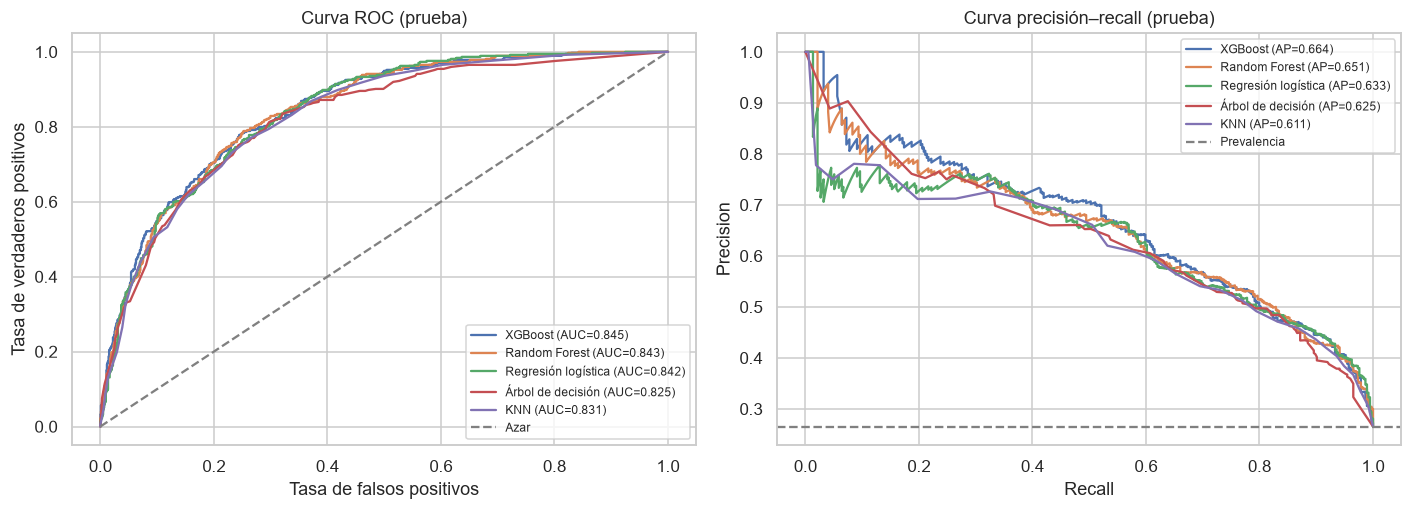

In [18]:
# 13. Curvas ROC y precisión–recall (prueba)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
colores = dict(zip(tabla_prueba.index, sns.color_palette("deep", len(tabla_prueba))))

for nombre in tabla_prueba.index:
    probabilidad = probabilidades_test[nombre]
    color = colores[nombre]

    fpr, tpr, _ = roc_curve(y_test, probabilidad)
    axes[0].plot(
        fpr,
        tpr,
        color=color,
        label=f"{nombre} (AUC={roc_auc_score(y_test, probabilidad):.3f})",
    )

    precision, recall, _ = precision_recall_curve(y_test, probabilidad)
    axes[1].plot(
        recall,
        precision,
        color=color,
        label=f"{nombre} (AP={average_precision_score(y_test, probabilidad):.3f})",
    )

axes[0].plot([0, 1], [0, 1], linestyle="--", color="gray", label="Azar")
axes[0].set_title("Curva ROC (prueba)")
axes[0].set_xlabel("Tasa de falsos positivos")
axes[0].set_ylabel("Tasa de verdaderos positivos")
axes[0].legend(fontsize=8)

axes[1].axhline(y_test.mean(), linestyle="--", color="gray", label="Prevalencia")
axes[1].set_title("Curva precisión–recall (prueba)")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].legend(fontsize=8)

fig.tight_layout()
plt.show()

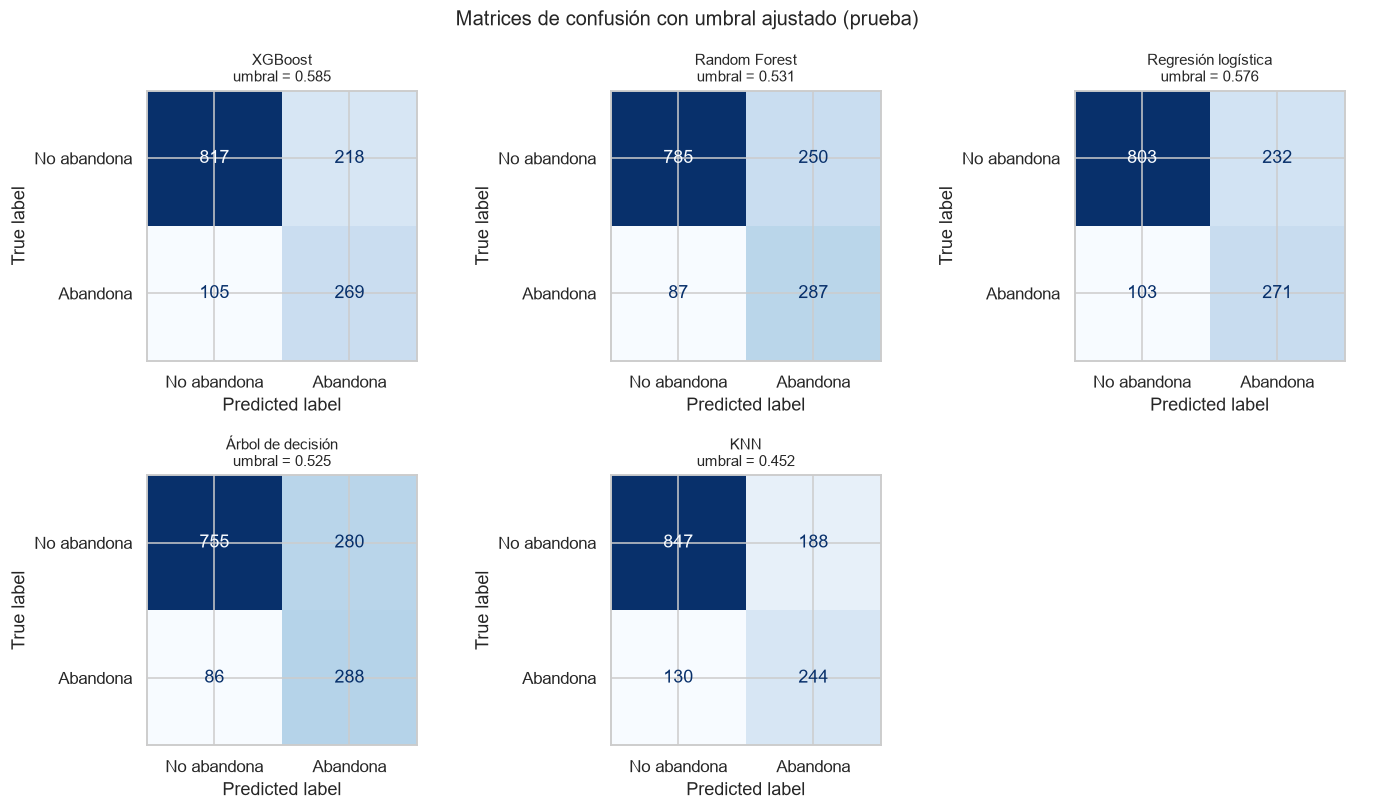

In [19]:
# 14. Matrices de confusión con el umbral ajustado
fig, axes = plt.subplots(2, 3, figsize=(13, 7.5))

for ax, nombre in zip(axes.ravel(), tabla_prueba.index):
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predicciones_test[nombre],
        display_labels=["No abandona", "Abandona"],
        cmap="Blues",
        colorbar=False,
        ax=ax,
    )
    ax.set_title(f"{nombre}\numbral = {umbrales[nombre]:.3f}", fontsize=10)

axes.ravel()[-1].axis("off")
fig.suptitle("Matrices de confusión con umbral ajustado (prueba)", fontsize=13)
fig.tight_layout()
plt.show()

Mayor riesgo condicional:
InternetService_Fiber optic   0.716
Contract_Month-to-month       0.663
TotalCharges                  0.474
StreamingMovies_Yes           0.283

Menor riesgo condicional:
tenure                             -1.141
Contract_Two year                  -0.766
MonthlyCharges                     -0.677
InternetService_DSL                -0.618
OnlineBackup_No internet service   -0.270


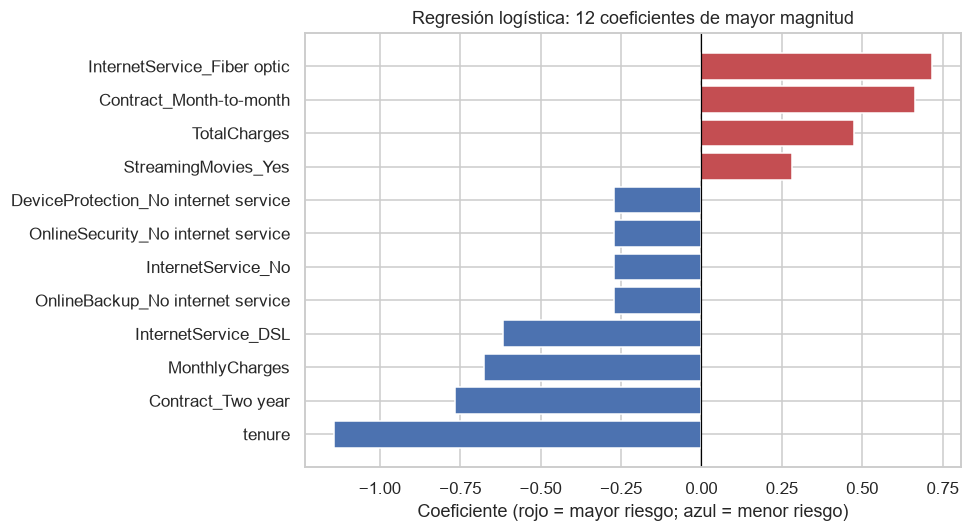

In [20]:
# 15. Interpretación: coeficientes de la regresión logística
# Coeficientes condicionales: tenure, MonthlyCharges y TotalCharges están
# correlacionadas, por lo que un signo puede invertirse al controlar por las demás.
# No deben leerse como efectos causales aislados.
modelo_lr = mejores_modelos["Regresión logística"]
nombres_lr = modelo_lr.named_steps["preprocesador"].get_feature_names_out()
coeficientes = modelo_lr.named_steps["clf"].coef_[0]

serie_lr = (
    pd.Series(coeficientes, index=nombres_lr)
    .rename(lambda nombre: nombre.replace("num_mediana__", "").replace("num_cero__", "").replace("cat__", ""))
    .sort_values(key=np.abs, ascending=False)
    .head(12)
    .sort_values()
)

print("Mayor riesgo condicional:")
print(serie_lr[serie_lr > 0].sort_values(ascending=False).head(5).to_string())
print("\nMenor riesgo condicional:")
print(serie_lr[serie_lr < 0].head(5).to_string())

fig, ax = plt.subplots(figsize=(9, 5))
colores_lr = ["#C44E52" if valor > 0 else "#4C72B0" for valor in serie_lr]
ax.barh(serie_lr.index, serie_lr.values, color=colores_lr)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Regresión logística: 12 coeficientes de mayor magnitud")
ax.set_xlabel("Coeficiente (rojo = mayor riesgo; azul = menor riesgo)")
fig.tight_layout()
plt.show()

Variables más importantes:
Contract_Month-to-month       0.152
tenure                        0.120
TotalCharges                  0.082
OnlineSecurity_No             0.074
Contract_Two year             0.070
TechSupport_No                0.057
MonthlyCharges                0.056
InternetService_Fiber optic   0.050


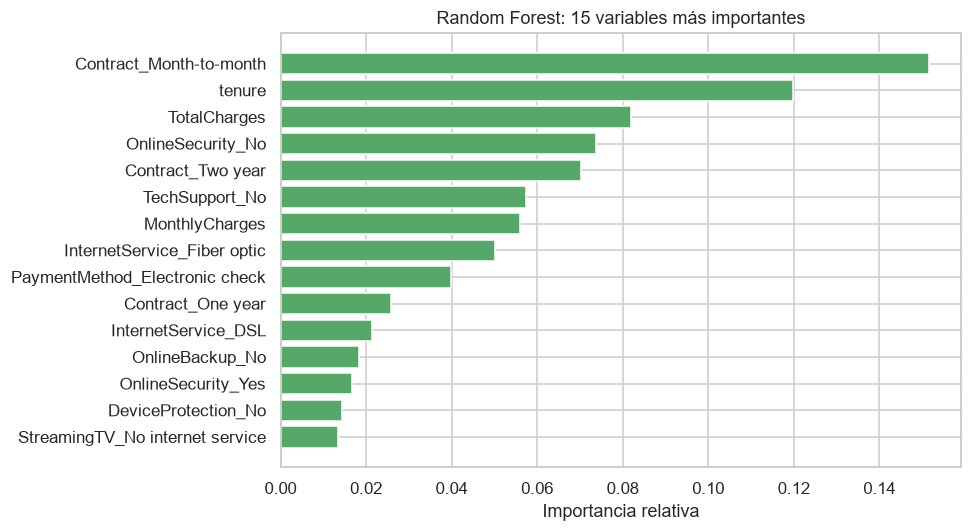

In [21]:
# 16. Interpretación: importancia de variables en Random Forest
modelo_rf = mejores_modelos["Random Forest"]
nombres_rf = modelo_rf.named_steps["preprocesador"].get_feature_names_out()
importancias = (
    pd.Series(
        modelo_rf.named_steps["clf"].feature_importances_,
        index=nombres_rf,
    )
    .rename(lambda nombre: nombre.replace("num_mediana__", "").replace("num_cero__", "").replace("cat__", ""))
    .sort_values(ascending=False)
    .head(15)
    .sort_values()
)

print("Variables más importantes:")
print(importancias.sort_values(ascending=False).head(8).to_string())

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(importancias.index, importancias.values, color="#55A868")
ax.set_title("Random Forest: 15 variables más importantes")
ax.set_xlabel("Importancia relativa")
fig.tight_layout()
plt.show()

In [22]:
# 17. Ranking final y recomendación
# Criterio: average precision; desempate por recall con umbral ajustado.
resumen_final = pd.DataFrame(
    {
        "Average precision": tabla_prueba["Average precision"],
        "Recall (umbral ajustado)": tabla_prueba["Recall (umbral ajustado)"],
        "Precision (umbral ajustado)": tabla_prueba["Precision (umbral ajustado)"],
        "F1 (umbral ajustado)": tabla_prueba["F1 (umbral ajustado)"],
        "ROC-AUC": tabla_prueba["ROC-AUC"],
    }
).sort_values(
    ["Average precision", "Recall (umbral ajustado)"],
    ascending=False,
)
resumen_final.insert(0, "Puesto", range(1, len(resumen_final) + 1))

recomendado = resumen_final.index[0]
fila_recomendada = resumen_final.loc[recomendado]

print(f"Modelo recomendado: {recomendado}")
print(
    f"  Average precision : {fila_recomendada['Average precision']:.3f}\n"
    f"  Recall            : {fila_recomendada['Recall (umbral ajustado)']:.3f}\n"
    f"  Precision         : {fila_recomendada['Precision (umbral ajustado)']:.3f}\n"
    f"  F1                : {fila_recomendada['F1 (umbral ajustado)']:.3f}\n"
    f"  ROC-AUC           : {fila_recomendada['ROC-AUC']:.3f}"
)

resumen_final.round(3)

Modelo recomendado: XGBoost
  Average precision : 0.664
  Recall            : 0.719
  Precision         : 0.552
  F1                : 0.625
  ROC-AUC           : 0.845


,Puesto,Average precision,Recall (umbral ajustado),Precision (umbral ajustado),F1 (umbral ajustado),ROC-AUC
Modelo,,,,,,
XGBoost,1,0.664,0.719,0.552,0.625,0.845
Random Forest,2,0.651,0.767,0.534,0.630,0.843
Regresión logística,3,0.633,0.725,0.539,0.618,0.842
Árbol de decisión,4,0.625,0.770,0.507,0.611,0.825
KNN,5,0.611,0.652,0.565,0.605,0.831
